###Predictive Classification using Random Forest Ensembles

In [1]:
#Upload the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

In [2]:
# Choose the  CSV file from the computer
from google.colab import files

uploaded = files.upload()
csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file)

print('Shape:', df.shape)
df.head()

Saving test_Y3wMUE5_7gLdaTN.csv.xls to test_Y3wMUE5_7gLdaTN.csv.xls
Shape: (367, 12)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,LP001015,Male,Yes,0,Graduate,No,5720,0,110.0,360.0,1.0,Urban
1,LP001022,Male,Yes,1,Graduate,No,3076,1500,126.0,360.0,1.0,Urban
2,LP001031,Male,Yes,2,Graduate,No,5000,1800,208.0,360.0,1.0,Urban
3,LP001035,Male,Yes,2,Graduate,No,2340,2546,100.0,360.0,NaN,Urban
4,LP001051,Male,No,0,Not Graduate,No,3276,0,78.0,360.0,1.0,Urban


In [3]:
#summary of data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 367 entries, 0 to 366
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            367 non-null    object 
 1   Gender             356 non-null    object 
 2   Married            367 non-null    object 
 3   Dependents         357 non-null    object 
 4   Education          367 non-null    object 
 5   Self_Employed      344 non-null    object 
 6   ApplicantIncome    367 non-null    int64  
 7   CoapplicantIncome  367 non-null    int64  
 8   LoanAmount         362 non-null    float64
 9   Loan_Amount_Term   361 non-null    float64
 10  Credit_History     338 non-null    float64
 11  Property_Area      367 non-null    object 
dtypes: float64(3), int64(2), object(7)
memory usage: 34.5+ KB


**Observation:**

 The dataset contains 12 columns with different data types, including numerical and categorical columns. Some columns contain missing values, which need to be handled before further analysis.

In [4]:
#check if any duplicates
df.duplicated().sum()

np.int64(0)

**Observation:**

 No duplicate rows were found in the dataset. Therefore, there was no need to remove duplicate records.

In [5]:
#check missing value
df.isnull().sum()

,0
Loan_ID,0
Gender,11
Married,0
Dependents,10
Education,0
Self_Employed,23
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,5
Loan_Amount_Term,6


**Observation:**

 The output shows the number of missing values present in each column. This helps identify which columns need data cleaning before analysis and model building.

In [6]:
#to find the total number of missing values
df.isnull().sum().sum()

np.int64(84)

**Observation:**

 The dataset initially contained 84 missing values across different columns. These missing values needed to be handled to improve data quality.

In [7]:
# To replace the missing values
#if the datatype is "Object" , replace it with mode of the particular column
#if the datatype is "int/float", repalce it with mean/median of the particular column

In [8]:
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])

In [9]:
df['Dependents'] = df['Dependents'].fillna(df['Dependents'].mode()[0])

In [10]:
df['Self_Employed'] = df['Self_Employed'].fillna(df['Self_Employed'].mode()[0])

In [11]:
df['LoanAmount'] = df['LoanAmount'].fillna(df['LoanAmount'].median())

In [12]:
df['Loan_Amount_Term'] = df['Loan_Amount_Term'].fillna(df['Loan_Amount_Term'].median())

In [13]:
df['Credit_History'] = df['Credit_History'].fillna(df['Credit_History'].median())

In [14]:
#to find the total number of missing values
df.isnull().sum().sum()

np.int64(0)

**Observation:**

Missing values in Gender, Dependents, and Self_Employed were replaced with their most frequently occurring values. This helped retain the records without deleting rows.

Missing values in LoanAmount, Loan_Amount_Term, and Credit_History were filled using the median of each column. Median imputation helps retain the data and is less affected by extreme numerical values than the mean.

After filling the missing values, the dataset contains zero missing values. Therefore, all the missing values handled by these steps have been successfully filled.

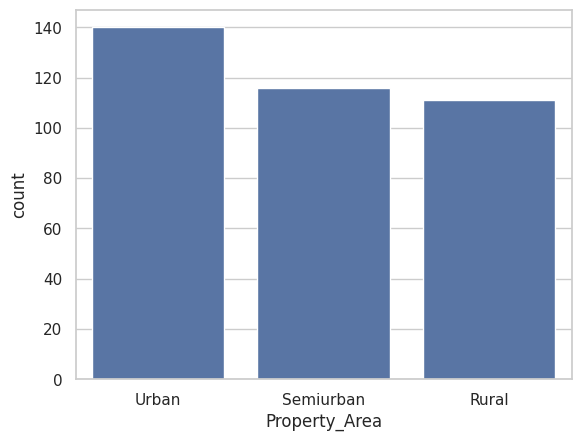

In [15]:
# Univariate Analysis
sns.countplot(x = 'Property_Area',data = df)
plt.show()

**Observation:**

 The count plot shows the number of applicants from Urban, Semiurban, and Rural areas. It helps us compare the number of applicants belonging to each property area.

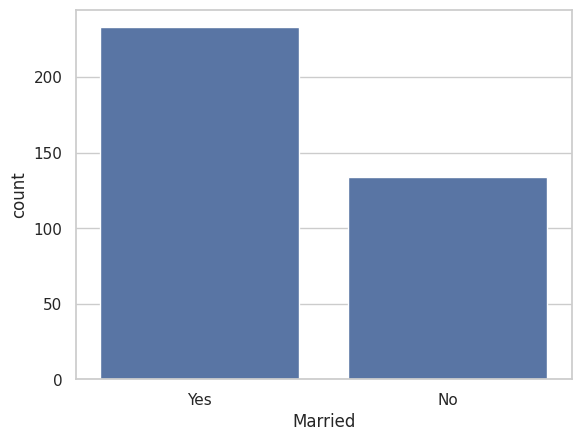

In [16]:
sns.countplot(x='Married',data=df)
plt.show()

**Observation:**

The count plot compares married and unmarried applicants. It helps us understand which marital-status category has more applicants in the dataset.

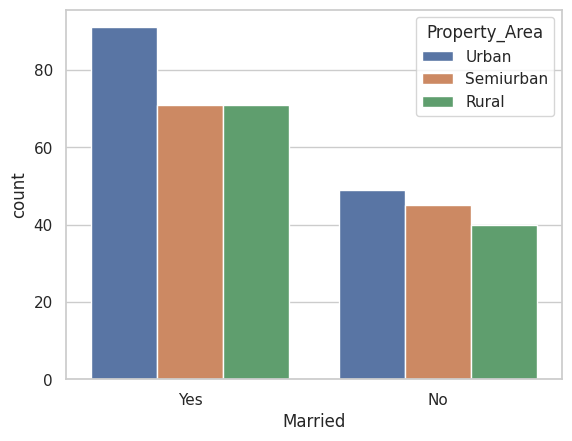

In [17]:
# Bivariate
sns.countplot(x = 'Married', hue = 'Property_Area', data = df)
plt.show()

**Observation:**

 The graph compares married and unmarried applicants across Urban, Semiurban, and Rural areas. It helps us understand how the distribution of marital status varies between property areas.

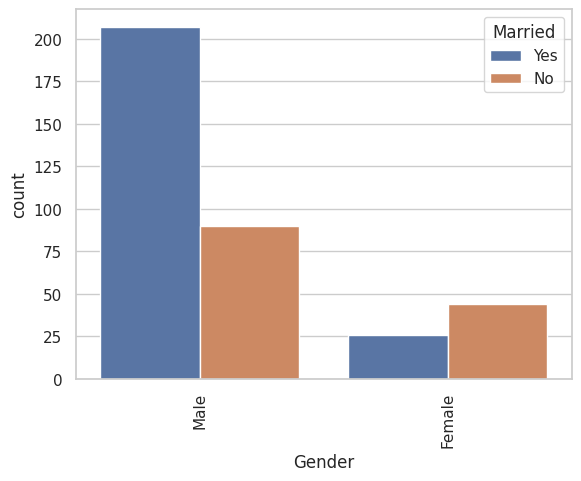

In [18]:
# Bivariate
sns.countplot(x = 'Gender', hue = 'Married', data = df)
plt.xticks(rotation = 90)
plt.show()

**Observation:**

The graph compares the marital status of male and female applicants. It helps us understand the distribution of married and unmarried applicants across genders.

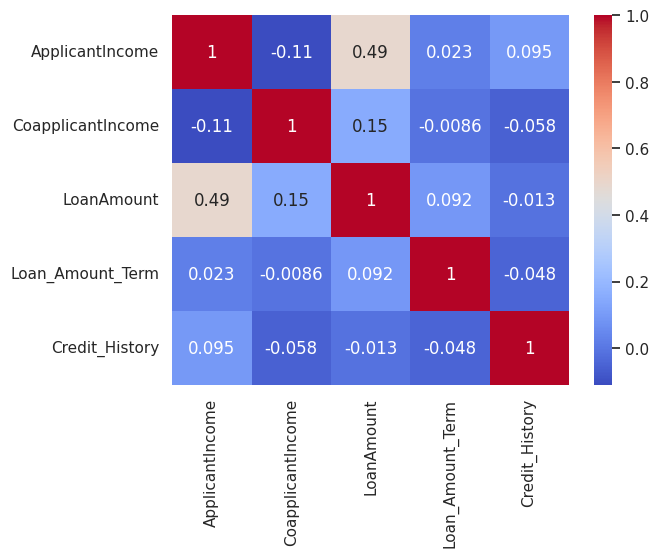

In [19]:
# Multi variate
numeric_df = df.select_dtypes(include = np.number)
corr = numeric_df.corr()
sns.heatmap(corr, annot = True,cmap = "coolwarm")
plt.show()


**Observation:**

The correlation heatmap shows the relationship between numerical columns in the dataset. Positive values indicate that two variables tend to increase together, while negative values indicate an opposite relationship. Values closer to zero indicate a weaker linear relationship.

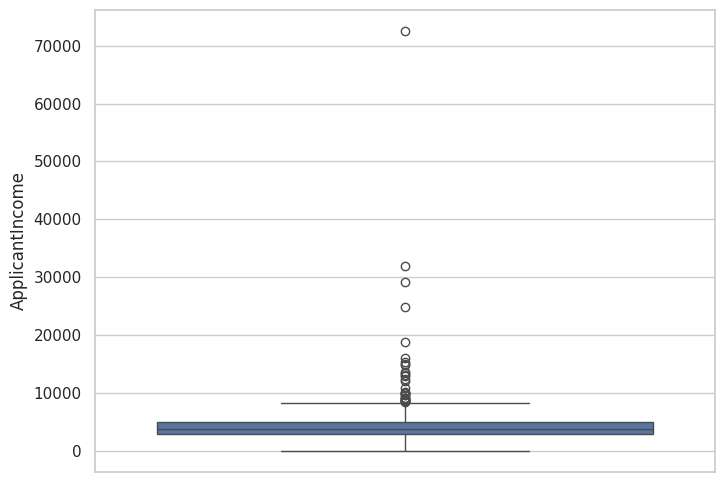

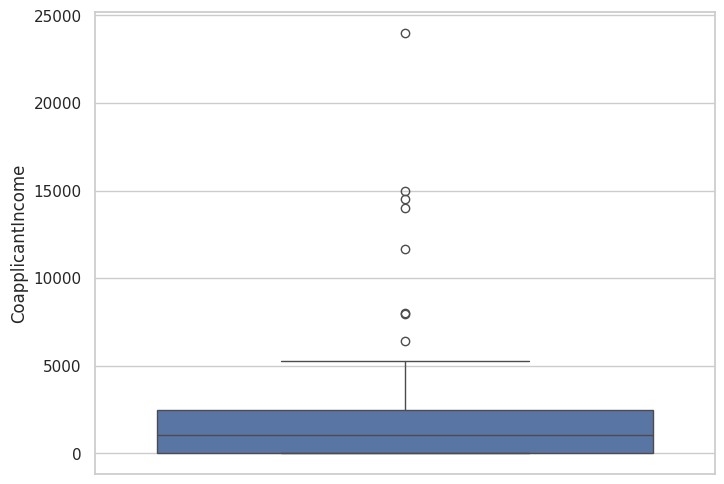

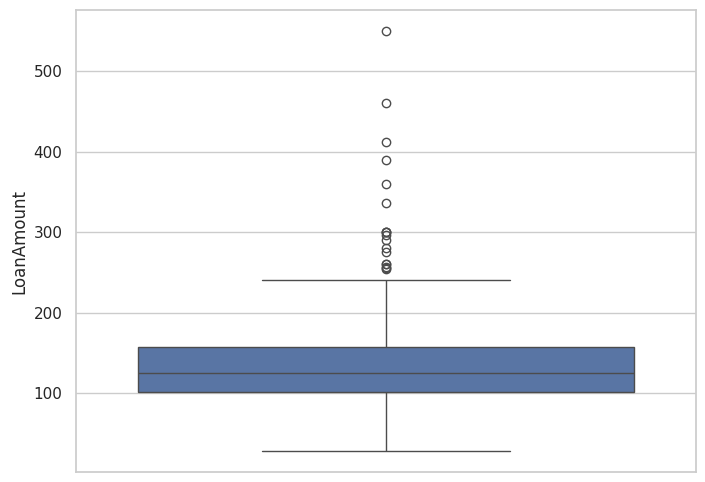

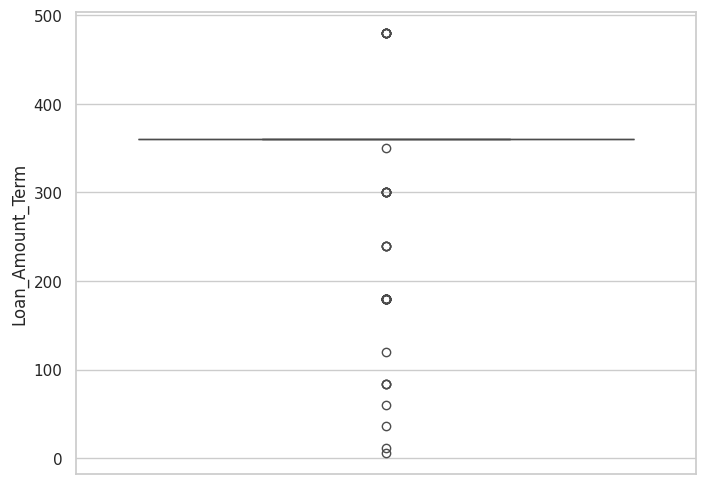

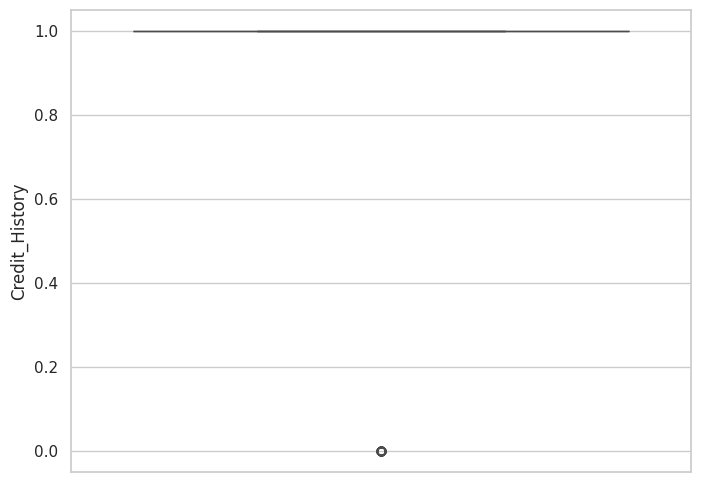

In [20]:
# Outlier check
cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History']
for col in cols:
  plt.figure(figsize = (8,6))
  sns.boxplot(df[col])
  plt.show()

In [23]:
# Handle outliers using the IQR method

cols = ['ApplicantIncome','CoapplicantIncome','LoanAmount','Loan_Amount_Term']

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df[col] = df[col].clip(
        lower=lower_limit,
        upper=upper_limit
    )

print("Outliers handled successfully!")

Outliers handled successfully!


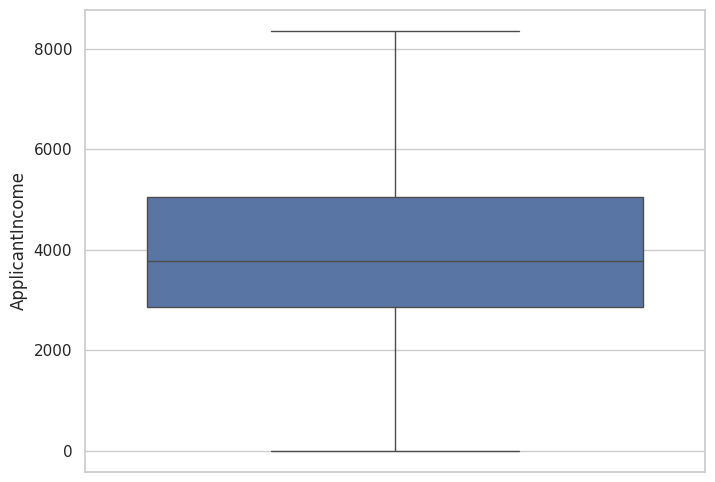

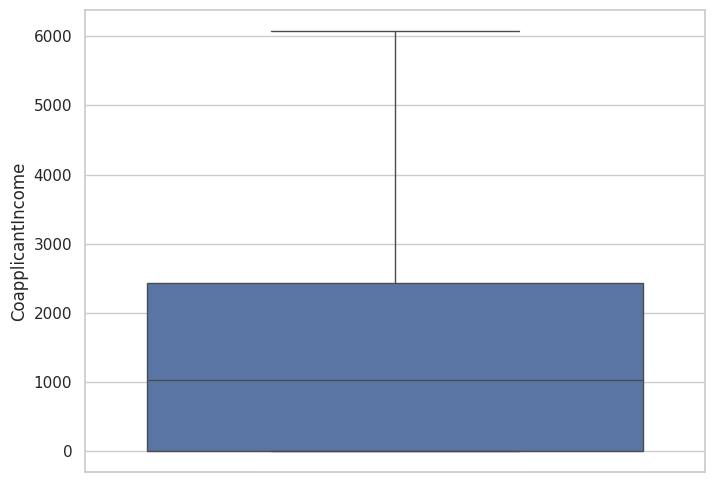

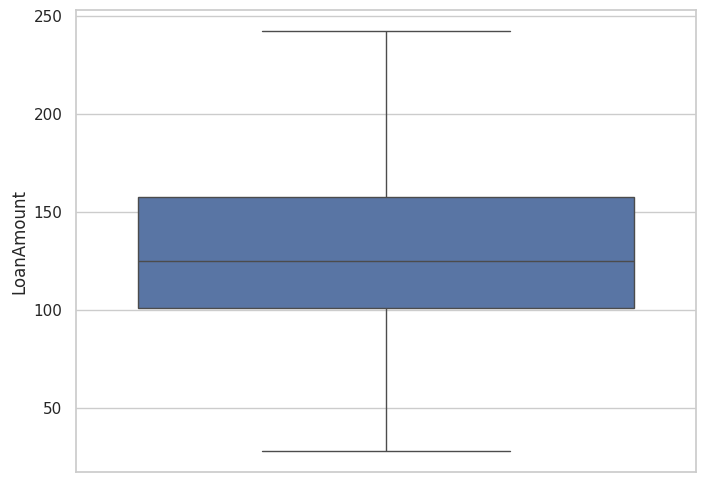

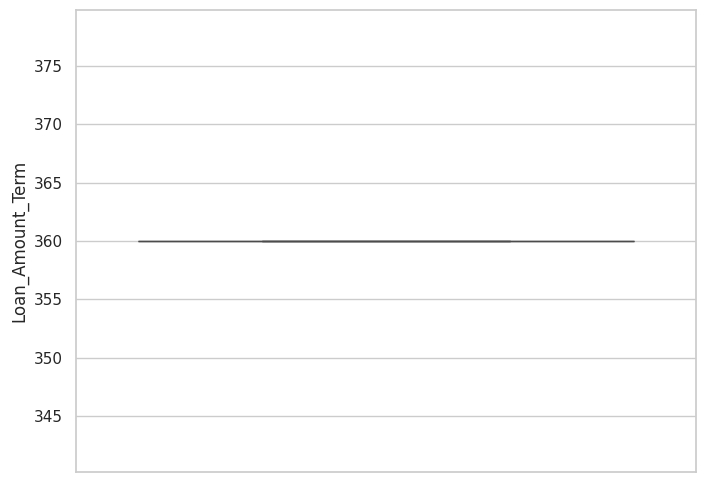

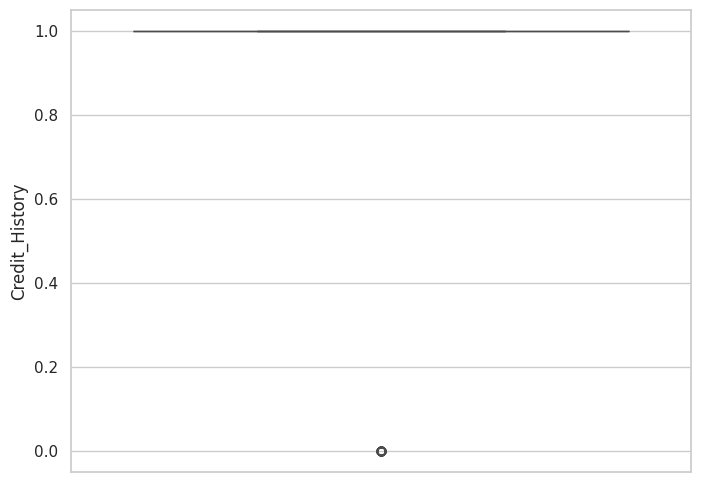

In [25]:
# Outlier check
cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History']
for col in cols:
  plt.figure(figsize = (8,6))
  sns.boxplot(df[col])
  plt.show()

**Observation:**

 Box plots were used to identify potential outliers in applicant income, co-applicant income, loan amount, loan term, and credit history. Points outside the whiskers indicate potential outliers. However, these points may represent valid observations rather than incorrect data.

  The IQR method was used to cap extreme values in four numerical columns. Values below the lower limit or above the upper limit were replaced with the respective limits, while the number of rows remained unchanged.

**Note:** Credit_History was excluded from capping because it generally represents binary categories, such as 0 and 1.

In [21]:
# Imbalance
df["Property_Area"].value_counts()

,count
Property_Area,
Urban,140
Semiurban,116
Rural,111


**Observation:** This displays the number of applicants belonging to Urban, Semiurban, and Rural areas. It helps identify which category has the highest and lowest number of applicants.

In [27]:
df.select_dtypes(include=['object']).columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'Property_Area'],
      dtype='object')

In [28]:
# Calculate the percentage distribution of each category in the Property_Area column
df["Property_Area"].value_counts(normalize= True)*100


,proportion
Property_Area,
Urban,38.147139
Semiurban,31.607629
Rural,30.245232


**Observation:**

Most loan applicants belong to the Urban area (38.15%). Semiurban areas account for 31.61% of applicants, while Rural areas account for 30.25%. This shows that applicants are distributed across all three areas, with Urban having the highest percentage.

In [31]:
from sklearn.model_selection import train_test_split
import pandas as pd

# 1. Define target variable (assuming 'Property_Area' as the target)
target_col = 'Property_Area'
y = df[target_col]

# 2. Drop target and identifiers to prepare features
X = df.drop(columns=['Loan_ID', target_col])

# 3. Convert categorical variables to numerical using One-Hot Encoding
X = pd.get_dummies(X, drop_first=True)

# 4. Perform the train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [32]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
import pandas as pd

# 1. Drop 'Loan_ID' as it's just an identifier
X = df.drop(columns=['Loan_ID'])

# 2. Identify target column (assuming 'Property_Area' as target since 'Loan_Status' is not in this dataset)
# Replace 'Property_Area' with 'Loan_Status' if you upload the training set later.
target_col = 'Property_Area'
y = df[target_col]
X = X.drop(columns=[target_col])

# 3. Convert categorical variables to dummy variables (One-Hot Encoding)
X = pd.get_dummies(X, drop_first=True)

# 4. Split the data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 5. Apply SMOTE Technique
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

In [33]:
# Display class counts before and after applying SMOTE
print("Before SMOTE:", y_train.value_counts())
print("After SMOTE:", y_train_smote.value_counts())

Before SMOTE: Property_Area
Urban        112
Semiurban     92
Rural         89
Name: count, dtype: int64
After SMOTE: Property_Area
Rural        112
Urban        112
Semiurban    112
Name: count, dtype: int64


**Observation:**

 SMOTE was applied to the training data to balance the target categories by generating synthetic samples for minority classes. The printed class counts show whether the categories became balanced after oversampling.

In [34]:
# Create and train the Random Forest classification model
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier()
model.fit(X_train_smote, y_train_smote)

RandomForestClassifier()

**Observation:** A Random Forest classifier was created and trained using the balanced training data. The model combines multiple decision trees to learn patterns and classify applicants into property-area categories.

In [35]:
# Predict target values for the training and testing datasets
y_train_pred=model.predict(X_train_smote)
y_test_pred=model.predict(X_test)

The trained model generated predictions for both the training and testing datasets. These predictions can be compared with the actual target values to evaluate model performance.

In [36]:
# Calculate accuracy on the training and testing datasets
from sklearn.metrics import accuracy_score
print(accuracy_score(y_train_pred, y_train_smote))
print(accuracy_score(y_test_pred, y_test))

0.9940476190476191
0.2972972972972973


**Observation:**

The Random Forest model achieved 99.40% accuracy on the training data but only 29.73% accuracy on the testing data. This shows that the model learned the training data very well but did not perform well on unseen data. This may be due to overfitting. The model needs improvement to make better predictions on new data.

In [37]:
# Classification Report
from sklearn.metrics import classification_report
print(classification_report(y_train_pred, y_train_smote))
print(classification_report(y_test_pred, y_test))

              precision    recall  f1-score   support

       Rural       0.98      1.00      0.99       110
   Semiurban       1.00      1.00      1.00       112
       Urban       1.00      0.98      0.99       114

    accuracy                           0.99       336
   macro avg       0.99      0.99      0.99       336
weighted avg       0.99      0.99      0.99       336

              precision    recall  f1-score   support

       Rural       0.41      0.33      0.37        27
   Semiurban       0.25      0.26      0.26        23
       Urban       0.25      0.29      0.27        24

    accuracy                           0.30        74
   macro avg       0.30      0.30      0.30        74
weighted avg       0.31      0.30      0.30        74



**Observation**

The Random Forest model achieved 99% accuracy on the training data, but only 30% accuracy on the testing data. The training results are very good, but the testing results are poor. This indicates that the model may be overfitting the training data and is not predicting unseen data accurately.
For the testing data, the Rural class achieved an F1-score of 0.37, Semiurban achieved 0.26, and Urban achieved 0.27. These results show that the model has difficulty correctly predicting all three property-area categories.

In [39]:
# hyperparameters
from sklearn.model_selection import GridSearchCV
param_grid = {
    'n_estimators': [50,100, 200, 300,500],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
model = RandomForestClassifier()
grid_search = GridSearchCV(estimator = model, param_grid = param_grid, cv = 5,n_jobs = -1,scoring ='f1_macro')
grid_search.fit(X_train_smote, y_train_smote)

GridSearchCV(cv=5, estimator=RandomForestClassifier(), n_jobs=-1,
             param_grid={'max_depth': [None, 5, 10],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [50, 100, 200, 300, 500]},
             scoring='f1_macro')

In [40]:
# Display the best parameters and best cross-validation score
print(grid_search.best_params_)
print(grid_search.best_score_)


{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
0.4804520182076624


**Observation:**


GridSearchCV was used to find the best hyperparameters for the Random Forest model by testing different combinations using 5-fold cross-validation. The best model was obtained with 200 trees, a maximum depth of 10, a minimum split size of 5, and a minimum leaf size of 2. This tuning helps select suitable model settings and may improve prediction performance. The model's final performance is checked using testing data.

In [42]:
# Select the Random Forest model with the best parameters
best_model = grid_search.best_estimator_

# Predict the target values for training data
y_train_pred = best_model.predict(X_train_smote)

# Predict the target values for testing data
y_test_pred = best_model.predict(X_test)

# Calculate and display training accuracy
print(accuracy_score(y_train_smote, y_train_pred))

# Calculate and display testing accuracy
print(accuracy_score(y_test, y_test_pred))

0.9255952380952381
0.32432432432432434


**Observation**

After hyperparameter tuning, the Random Forest model achieved 92.56% training accuracy and 32.43% testing accuracy. The training accuracy is much higher than the testing accuracy, indicating that the model may still be overfitting and is not performing well on unseen data. Although tuning reduced the training accuracy, the testing accuracy improved slightly from 29.73% to 32.43%.

###**Conclusion**

In this project, I performed data analysis and implemented a Random Forest Classification model using the Loan Prediction dataset. I handled missing values, checked duplicates, performed exploratory data analysis (EDA), and treated outliers using the IQR method. I also applied one-hot encoding and SMOTE to prepare the data for model training. Hyperparameter tuning was performed using GridSearchCV to find suitable model settings.
The final model achieved 92.56% training accuracy and 32.43% testing accuracy. The difference between these values indicates that the model may be overfitting and needs further improvement.
Since the available dataset did not contain the Loan_Status column, the model was trained to predict Property_Area (Rural, Semiurban, or Urban) rather than loan approval. Overall, this project helped me understand data preprocessing, visualization, Random Forest classification, and hyperparameter tuning.